# Road to Safety — Temporal robustness and calibration v1

## tl;dr

Six expanding-history evaluations compare unchanged, intercept-only and sigmoid-calibrated probabilities for **2014–2019**. Each year's estimator uses1999 through`t−3`, calibration uses`t−2` and`t−1`, and evaluation uses`t`. Every method uses the same approved eight categorical condition features; no2020–2021 observations are fitted, calibrated or scored.

The predeclared rule selects **sigmoid** for developmental follow-up. The results below distinguish raw average-score ranking from eligibility under the multi-year consistency and Brier guardrails. This is not a deployed model or a new independent holdout test: these historical years were previously examined.

See [results](../docs/temporal_calibration_v1_results.md), [protocol](../docs/temporal_calibration_v1_protocol.md), [experiment card](../models/temporal_calibration_v1_card.md) and [independent validation](../docs/temporal_calibration_v1_validation.md).

Macro log loss is **0.07373510 unchanged**, **0.07370461 intercept-only**, and **0.07370303 sigmoid**. The selected method's gain is **0.00003207**, about **0.0435% relative**. Both corrections improve 2014–2017 and worsen **2018–2019**; this is a marginal historical improvement, not a demonstrated fix for a later shift.

## Context & Methods

### Key Assumptions

The population is recorded fatal/nonfatal-injury candidate collisions from the pinned NCDB releases, not all traffic exposure or individual road users. The target is the same collision-level binary severity outcome. All eligible events and documented unknown/other/unavailable categories are retained; there is no complete-case filter or class balancing.

For evaluation year`t`=2014,…,2019, fit a fresh fixed L2 logistic model on1999…t−3, fit calibration on t−2…t−1, evaluate on t. Base settings, categorical dictionary domains and dropped references match the original frozen baseline. Year/IDs/outcomes/diagnostics do not enter predictors. Later folds can include earlier evaluation years in their history; folds are dependent.

For base logit`z`, the three candidate probabilities are`expit(z)`, `expit(z+delta)` and`expit(a*z+b)`. Calibration maximizes unpenalized binomial likelihood on calibration years only using stable logaddexp and analytic gradients; sigmoid slope is bounded at a≥1e-6. The training-prevalence comparator remains separate from calibration-method selection.

The primary selection score is the equally weighted mean of six annual evaluation log losses. A calibrated candidate is eligible only if it improves that mean by more than1e-10, improves at least4/6 years, and does not worsen macro Brier beyond1e-10. Choose the lowest eligible macro log loss; ties within tolerance choose the simpler method. Otherwise retain unchanged.

Report annual, macro mean/sample SD, clearly labeled pooled scores, calibration-bin counts and availability groups. Fold SD is descriptive, not a confidence interval. Positive monotone calibration preserves theoretical within-fold ranking; applying different calibrators across folds can change pooled ranking.

### Reproduction

```bash
uv sync --locked --python 3.13 --extra notebook
OPENBLAS_NUM_THREADS=2 OMP_NUM_THREADS=2 MPLCONFIGDIR=/tmp/road-to-safety-mpl .venv/bin/python -m road_to_safety.fit_temporal_calibration_v1
.venv/bin/python -m road_to_safety.validate_temporal_calibration_v1
```

Run fitting only to regenerate the six-fold experiment. This notebook reads the saved, fingerprinted run and independently validates it without refitting. Plotting and calculation code remains editable in the source modules.

## Data

### Frozen fold design and saved run

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
protocol=json.loads((ROOT/'data/reference/temporal_calibration_v1_protocol.json').read_text())
print('Experiment:',protocol['experiment_id'],'Frozen:',protocol['frozen_at_utc'])
display(pd.DataFrame([{'evaluation_year':f['evaluation_year'],'fit_start':f['train']['start_year'],'fit_end':f['train']['end_year'],'calibration_start':f['calibration']['start_year'],'calibration_end':f['calibration']['end_year']} for f in protocol['folds']]))
def table(name): return pd.read_csv(ROOT/'reports/tables'/name)
def figure(name): display(Image(filename=str(ROOT/'reports/figures'/name),width=1100))

Experiment: temporal_calibration_v1 Frozen: 2026-10-18T21:27:24.265691+00:00


,evaluation_year,fit_start,fit_end,calibration_start,calibration_end
0,2014,1999,2011,2012,2013
1,2015,1999,2012,2013,2014
2,2016,1999,2013,2014,2015
3,2017,1999,2014,2015,2016
4,2018,1999,2015,2016,2017
5,2019,1999,2016,2017,2018


### Independent source, score and likelihood checks

The independent auditor reconstructs base logits and all calibrated probabilities, checks training/calibration likelihood stationarity and source-linked fold membership, and recomputes metrics, bins and selection. This notebook verifies that its passed receipt, validator code and all bound inputs/outputs remain current; the CLI above reruns the full audit when needed. It does not repeat the full source scan merely to display unchanged results.

In [2]:
import hashlib
sha=lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
folder=ROOT/'data/derived/temporal_calibration_v1'
validation=json.loads((folder/'validation.json').read_text())
assert validation['status']=='passed' and not validation['failures']
for path,digest in validation['input_fingerprints'].items():
    assert sha(ROOT/path)==digest,path
assert sha(ROOT/'src/road_to_safety/validate_temporal_calibration_v1.py')==validation['validator_sha256']
manifest=json.loads((folder/'manifest.json').read_text())
for section in ['input_fingerprints','artifacts']:
    for path,digest in manifest[section].items():
        assert sha(ROOT/path)==digest,path
for path,digest in protocol['input_fingerprints'].items():
    assert sha(ROOT/path)==digest,path
ledger=table('tcal_v1_validation_checks.csv')
assert ledger.status.eq('passed').all()
assert ledger['check'].tolist()==validation['checks_passed']
print('Independent audit passed:',len(validation['checks_passed']),'checks; all saved-run fingerprints current.')

Independent audit passed: 44 checks; all saved-run fingerprints current.


## Results

### Annual probability performance

Log loss and Brier are proper probability scores. Lower is better. Their improvement is not by itself proof of calibration at every risk level. Compare all methods on the same year’s collisions.

In [3]:
metrics=table('tcal_v1_metrics.csv')
annual=metrics[metrics.phase.eq('evaluation') & metrics['group'].eq('all')]
display(annual[['eval_year','method','n','fatal','observed_prevalence','mean_prediction','log_loss','brier_score','average_precision','roc_auc']])

,eval_year,method,n,fatal,observed_prevalence,mean_prediction,log_loss,brier_score,average_precision,roc_auc
40,2014,unchanged,116292,1675,0.014403,0.015876,0.071647,0.014077,0.033364,0.704350
41,2014,intercept_only,116292,1675,0.014403,0.014561,0.071576,0.014074,0.033364,0.704350
42,2014,sigmoid,116292,1675,0.014403,0.014561,0.071576,0.014074,0.033364,0.704350
43,2014,prevalence,116292,1675,0.014403,0.016586,0.075527,0.014201,0.014403,0.500000
248,2015,unchanged,119550,1693,0.014161,0.015799,0.070720,0.013846,0.033455,0.701599
249,2015,intercept_only,119550,1693,0.014161,0.014516,0.070634,0.013842,0.033455,0.701599
250,2015,sigmoid,119550,1693,0.014161,0.014516,0.070634,0.013842,0.033455,0.701599
251,2015,prevalence,119550,1693,0.014161,0.016475,0.074523,0.013966,0.014161,0.500000
456,2016,unchanged,118321,1738,0.014689,0.015812,0.073164,0.014365,0.032920,0.693441
457,2016,intercept_only,118321,1738,0.014689,0.014391,0.073125,0.014361,0.032920,0.693441


### Equal-year summary and predeclared recommendation

Each evaluation year gets equal weight in selection. The selected method is developmental evidence, not independent prospective validation. Fold sample SD does not measure a guaranteed uncertainty range.

In [4]:
display(table('tcal_v1_macro.csv'))
display(table('tcal_v1_selection.csv'))
print(json.loads((ROOT/'data/derived/temporal_calibration_v1/selection.json').read_text())['selected_method'])

,method,log_loss_mean,log_loss_std,brier_score_mean,brier_score_std,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,mean_prediction_mean,mean_prediction_std,observed_prevalence_mean,observed_prevalence_std,prediction_minus_observed_mean,prediction_minus_observed_std,observed_expected_ratio_mean,observed_expected_ratio_std
0,intercept_only,0.073705,0.002517,0.014545,0.000593,0.033757,0.001201,0.697798,0.004421,0.014643,0.000269,0.014889,0.000618,-0.000246,0.000484,1.016661,0.032966
1,prevalence,0.077488,0.002519,0.014669,0.000597,0.014889,0.000618,0.500000,0.000000,0.016318,0.000193,0.014889,0.000618,0.001429,0.000796,0.912843,0.047874
2,sigmoid,0.073703,0.002516,0.014545,0.000593,0.033757,0.001201,0.697798,0.004421,0.014644,0.000271,0.014889,0.000618,-0.000245,0.000483,1.016604,0.032957
3,unchanged,0.073735,0.002471,0.014547,0.000591,0.033757,0.001201,0.697798,0.004421,0.015728,0.000157,0.014889,0.000618,0.000840,0.000751,0.946964,0.047501


,method,macro_log_loss,macro_brier_score,macro_log_loss_difference,macro_brier_difference,years_log_loss_improved,raw_macro_log_loss_rank,eligible
0,unchanged,0.073735,0.014547,0.000000,0.000000,0,3,True
1,intercept_only,0.073705,0.014545,-0.000030,-0.000002,4,2,True
2,sigmoid,0.073703,0.014545,-0.000032,-0.000002,4,1,True


sigmoid


### Probability scores and calibration gap by year

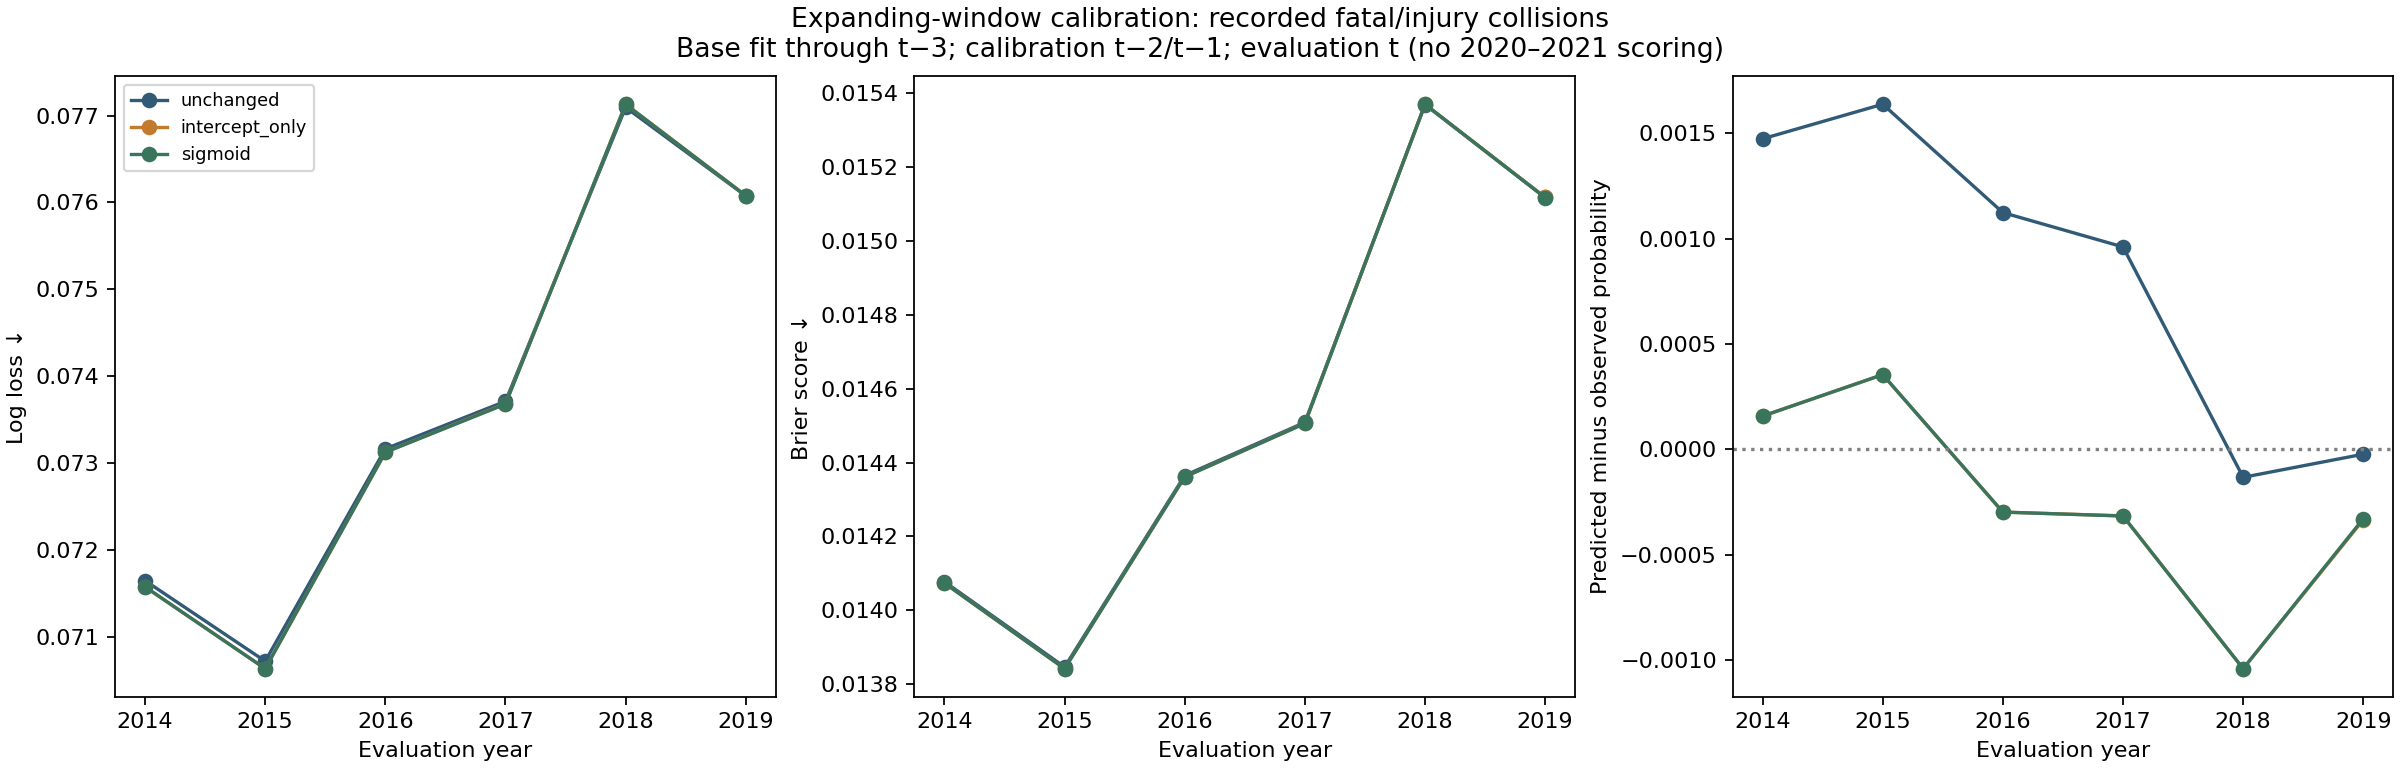

In [5]:
figure('tcal_v1_annual_scores.png')

### Reliability across evaluation years

The low-probability bin edges are frozen in advance, alongside the original ten equal-width bins. Empty/sparse bins remain in evidence. Points with few observations are unstable and do not establish individual risk accuracy.

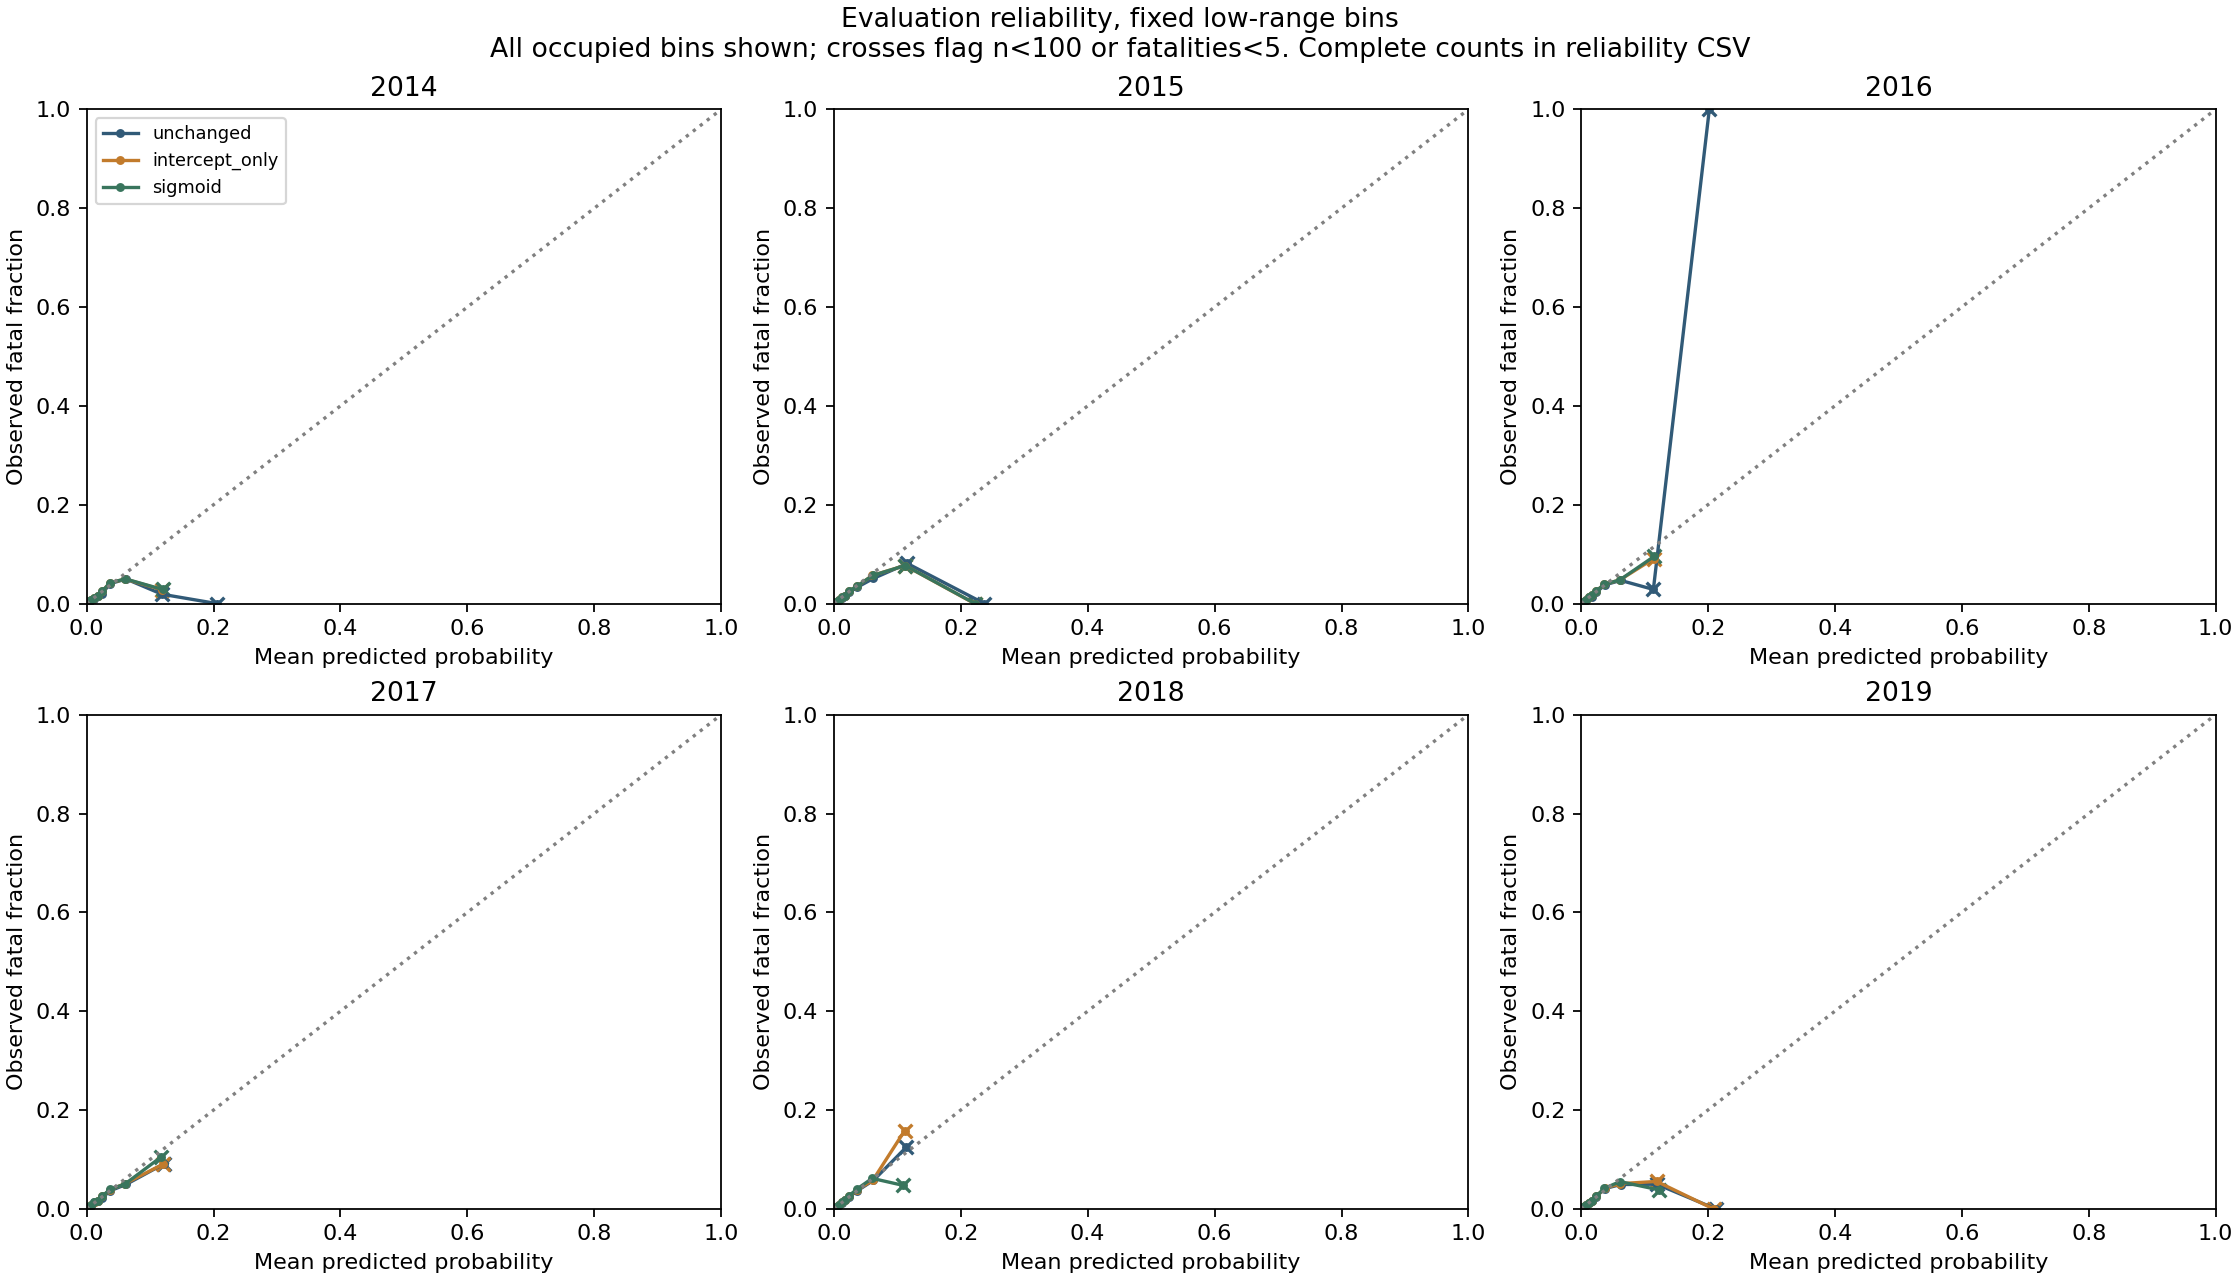

In [6]:
figure('tcal_v1_reliability.png')

### Low-probability zoom

The full-support figure above retains an extreme sparse bin. This supplementary zoom shows the bulk probability range and explicitly counts observations in bins outside either displayed axis, separately for each method. It changes no bin definition, score or selection rule.

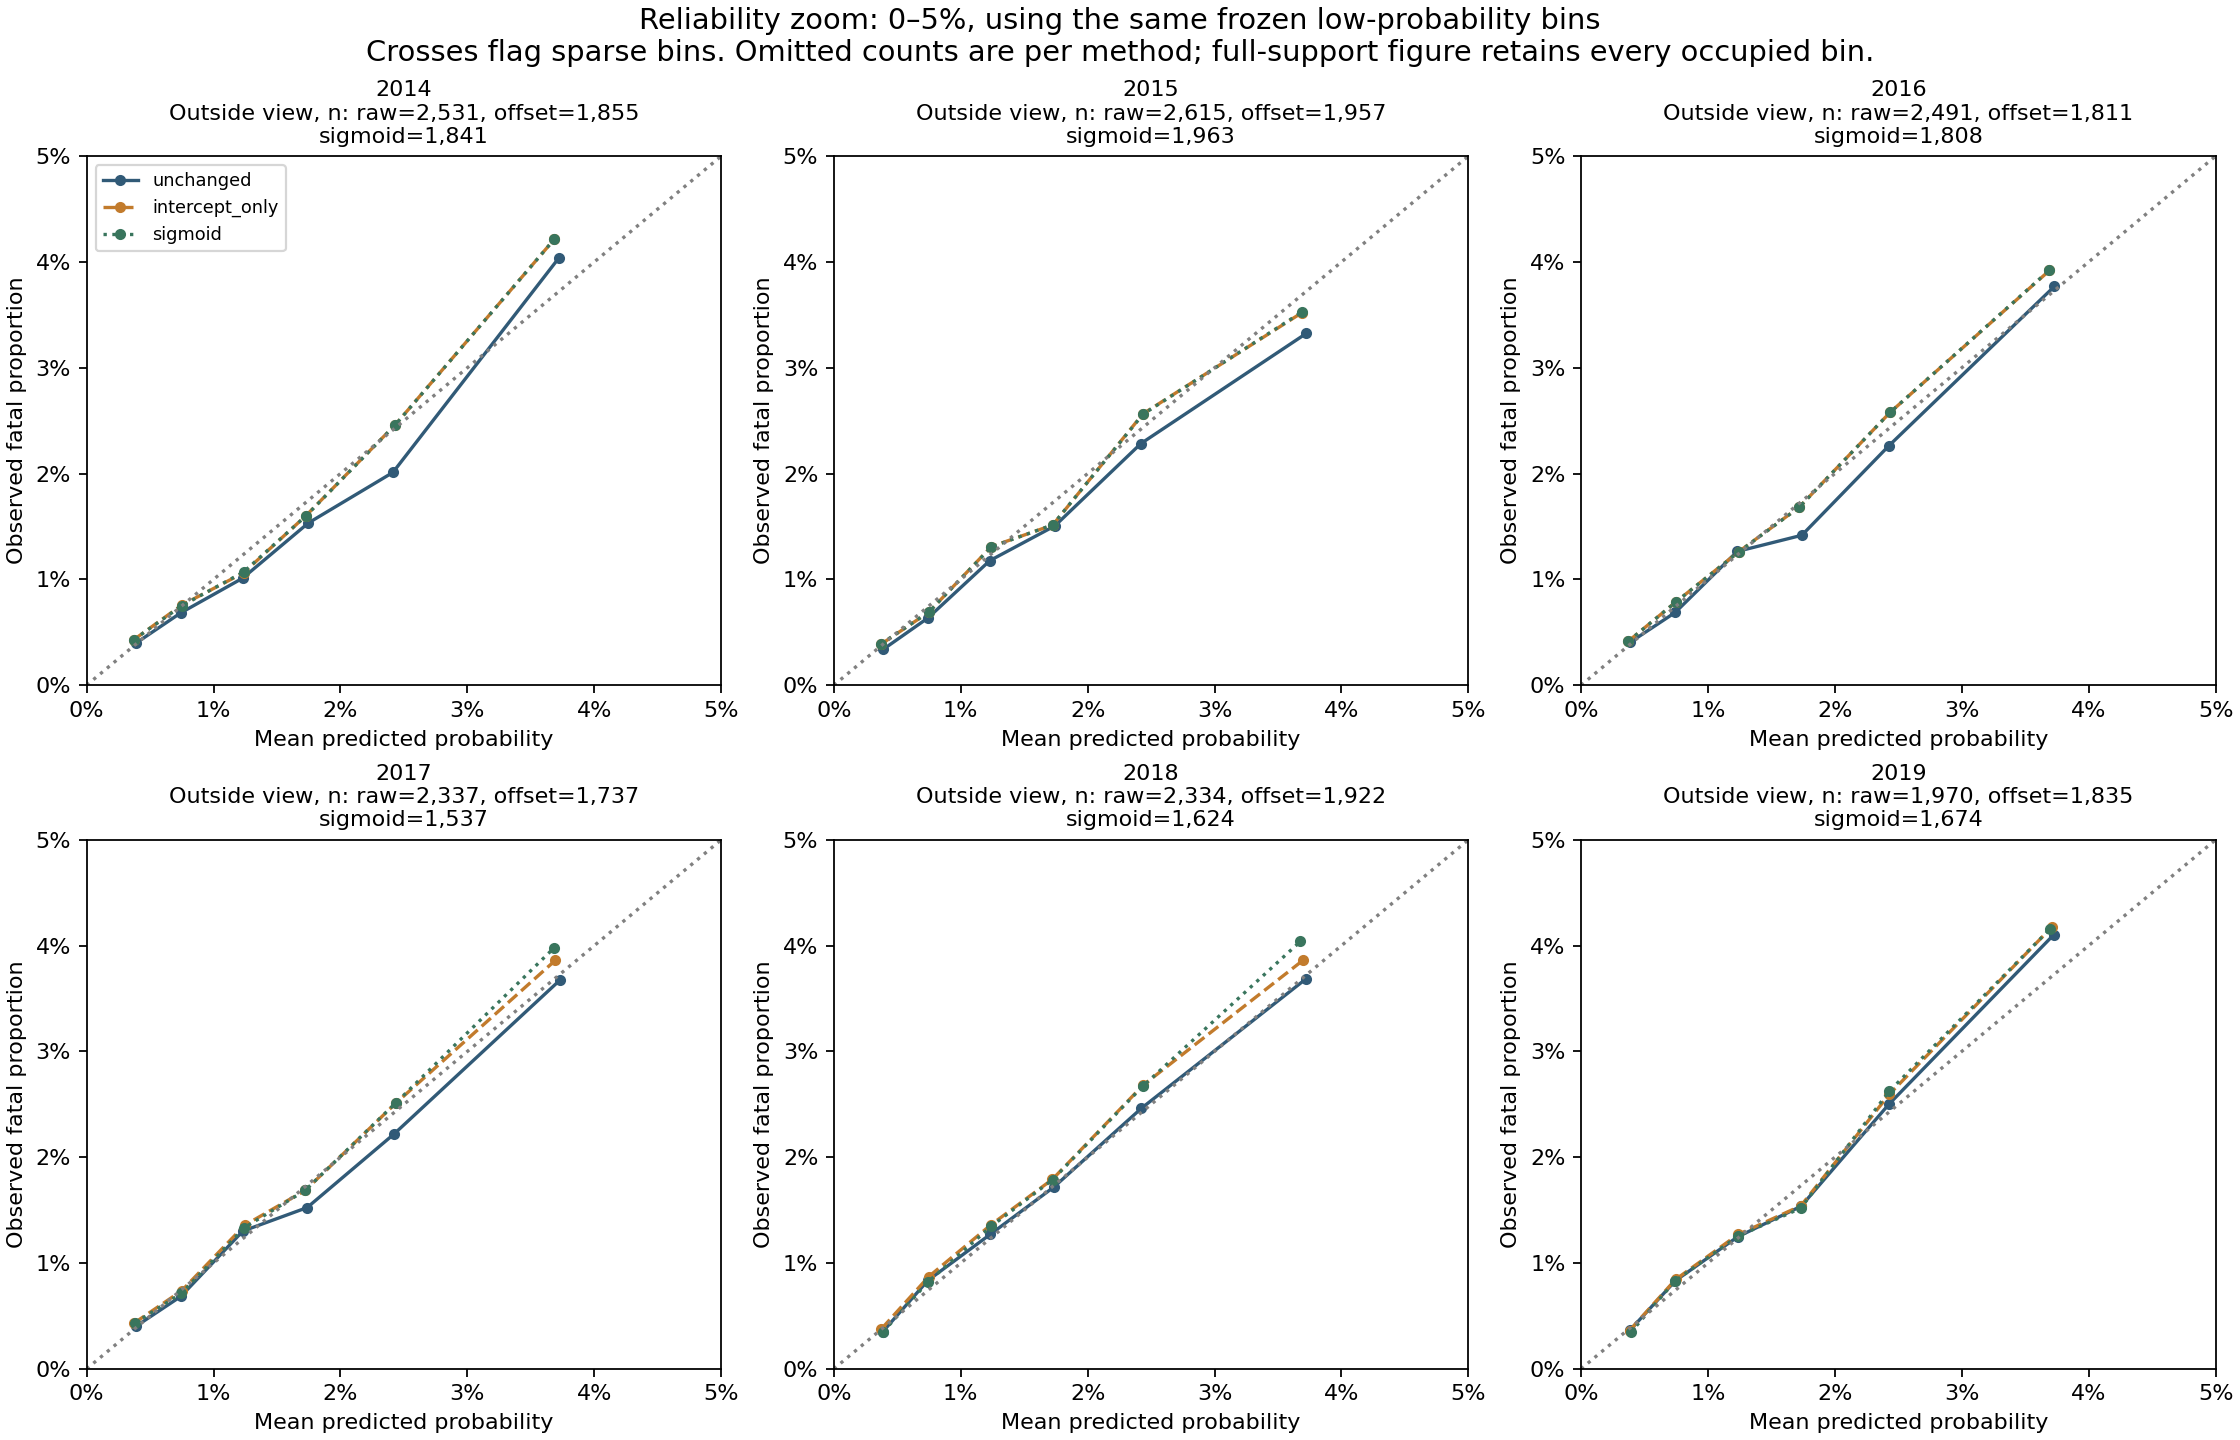

In [7]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

zoom_bins=table('tcal_v1_reliability.csv')
zoom_bins=zoom_bins[zoom_bins.phase.eq('evaluation') & zoom_bins.scheme.eq('low_probability') & zoom_bins.n.gt(0)]
colors={'unchanged':'#315a77','intercept_only':'#c27b2c','sigmoid':'#39755d'}
styles={'unchanged':'-','intercept_only':'--','sigmoid':':'}
short={'unchanged':'raw','intercept_only':'offset','sigmoid':'sigmoid'}
fig,axes=plt.subplots(2,3,figsize=(14,9),layout='constrained')
for axis,year in zip(axes.flat,range(2014,2020)):
    omitted={}
    for method in colors:
        values=zoom_bins[zoom_bins.eval_year.eq(year) & zoom_bins.method.eq(method)]
        visible=values.mean_prediction.le(.05) & values.observed_fraction.le(.05)
        omitted[method]=int(values.loc[~visible,'n'].sum())
        shown=values[visible]
        axis.plot(shown.mean_prediction,shown.observed_fraction,styles[method],marker='o',markersize=4,label=method,color=colors[method])
        sparse=shown[shown.n.lt(100) | shown.fatal.lt(5)]
        axis.scatter(sparse.mean_prediction,sparse.observed_fraction,marker='x',s=50,color=colors[method])
    axis.plot([0,.05],[0,.05],':',color='gray')
    axis.set(xlim=(0,.05),ylim=(0,.05),xlabel='Mean predicted probability',ylabel='Observed fatal proportion')
    axis.xaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    axis.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    axis.set_title(f"{year}\nOutside view, n: raw={omitted['unchanged']:,}, offset={omitted['intercept_only']:,}\nsigmoid={omitted['sigmoid']:,}",fontsize=10)
axes.flat[0].legend(fontsize=8,loc='upper left')
fig.suptitle('Reliability zoom: 0–5%, using the same frozen low-probability bins\nCrosses flag sparse bins. Omitted counts are per method; full-support figure retains every occupied bin.',fontsize=13)
zoom_path=ROOT/'reports/figures/tcal_v1_reliability_zoom.png'
fig.savefig(zoom_path,dpi=160)
plt.close(fig)
figure(zoom_path.name)


In [8]:
bins=table('tcal_v1_reliability.csv')
print('All-bin evidence:',len(bins),'rows, including empty bins')
display(bins[bins.phase.eq('evaluation') & bins.eval_year.eq(2019) & bins.scheme.eq('low_probability') & bins.n.gt(0)])
display(table('tcal_v1_ece.csv').query("phase == 'evaluation' and scheme == 'low_probability'"))

All-bin evidence: 1008 rows, including empty bins


,eval_year,phase,method,scheme,bin,left,right,n,sparse_n_lt_100_or_fatal_lt_5,fatal,mean_prediction,observed_fraction
934,2019,evaluation,unchanged,low_probability,0,0.000,0.005,17512,False,64,0.003857,0.003655
935,2019,evaluation,unchanged,low_probability,1,0.005,0.010,24011,False,200,0.007436,0.008330
936,2019,evaluation,unchanged,low_probability,2,0.010,0.015,19370,False,242,0.012360,0.012494
937,2019,evaluation,unchanged,low_probability,3,0.015,0.020,17636,False,271,0.017342,0.015366
938,2019,evaluation,unchanged,low_probability,4,0.020,0.030,15238,False,381,0.024256,0.025003
939,2019,evaluation,unchanged,low_probability,5,0.030,0.050,8893,False,365,0.037260,0.041044
940,2019,evaluation,unchanged,low_probability,6,0.050,0.100,1929,False,95,0.062373,0.049248
941,2019,evaluation,unchanged,low_probability,7,0.100,0.200,40,True,2,0.119342,0.050000
942,2019,evaluation,unchanged,low_probability,8,0.200,0.300,1,True,0,0.212264,0.000000
955,2019,evaluation,intercept_only,low_probability,0,0.000,0.005,18226,False,66,0.003823,0.003621


,eval_year,phase,method,scheme,n,ece
9,2014,evaluation,intercept_only,low_probability,116292,0.001315
11,2014,evaluation,prevalence,low_probability,116292,0.002182
13,2014,evaluation,sigmoid,low_probability,116292,0.001280
15,2014,evaluation,unchanged,low_probability,116292,0.002101
25,2015,evaluation,intercept_only,low_probability,119550,0.001003
27,2015,evaluation,prevalence,low_probability,119550,0.002313
29,2015,evaluation,sigmoid,low_probability,119550,0.000994
31,2015,evaluation,unchanged,low_probability,119550,0.001637
41,2016,evaluation,intercept_only,low_probability,118321,0.000829
43,2016,evaluation,prevalence,low_probability,118321,0.001672


### Calibration parameters and support

Intercept-only changes average odds while holding the base score slope fixed; sigmoid changes both slope and intercept. Both adjustments use only the two prior calibration years. All parameters are archived for independent reconstruction.

In [9]:
rows=[]
for year in range(2014,2020):
    model=json.loads((ROOT/f'data/derived/temporal_calibration_v1/model_{year}.json').read_text())
    for method,parameters in model['calibrators'].items():
        rows.append({'eval_year':year,'method':method,'slope':parameters['slope'],'intercept':parameters['intercept'],'iterations':parameters['iterations'],'converged':parameters['converged']})
display(pd.DataFrame(rows))
support=table('tcal_v1_level_support.csv')
display(support.groupby('eval_year')[['train_unobserved']].sum())

,eval_year,method,slope,intercept,iterations,converged
0,2014,unchanged,1.000000,0.000000,0,True
1,2014,intercept_only,1.000000,-0.088676,4,True
2,2014,sigmoid,0.998761,-0.093452,15,True
3,2015,unchanged,1.000000,0.000000,0,True
4,2015,intercept_only,1.000000,-0.086812,4,True
5,2015,sigmoid,1.001192,-0.082194,14,True
6,2016,unchanged,1.000000,0.000000,0,True
7,2016,intercept_only,1.000000,-0.096484,4,True
8,2016,sigmoid,0.998869,-0.100868,15,True
9,2017,unchanged,1.000000,0.000000,0,True


,train_unobserved
eval_year,
2014,11
2015,11
2016,11
2017,11
2018,11
2019,11


### Availability groups and source membership

Unknown, unavailable and other are separate; presence flags may overlap. Hierarchical status groups use unknown/unavailable precedence over other. Zero-support groups have undefined probability/ranking metrics, not invented zeros. These summaries overlap across features and must not be added as unique collisions.

In [10]:
availability=metrics[metrics.phase.eq('evaluation') & metrics['group'].isin(['has_unknown=True','has_other=True'])]
display(availability[['eval_year','group','method','n','fatal','log_loss','mean_prediction','observed_prevalence','sparse_n_lt_100_or_fatal_lt_5']])
member=table('tcal_v1_membership.csv')
display(member.groupby(['eval_year','phase'])[['n','fatal']].sum())

,eval_year,group,method,n,fatal,log_loss,mean_prediction,observed_prevalence,sparse_n_lt_100_or_fatal_lt_5
68,2014,has_other=True,unchanged,9741,158,0.079387,0.018652,0.016220,False
69,2014,has_other=True,intercept_only,9741,158,0.079241,0.017109,0.016220,False
70,2014,has_other=True,sigmoid,9741,158,0.079241,0.017107,0.016220,False
71,2014,has_other=True,prevalence,9741,158,0.082943,0.016586,0.016220,False
276,2015,has_other=True,unchanged,8720,116,0.067364,0.018317,0.013303,False
277,2015,has_other=True,intercept_only,8720,116,0.066994,0.016831,0.013303,False
278,2015,has_other=True,sigmoid,8720,116,0.066993,0.016832,0.013303,False
279,2015,has_other=True,prevalence,8720,116,0.071011,0.016475,0.013303,False
484,2016,has_other=True,unchanged,8375,130,0.077626,0.018774,0.015522,False
485,2016,has_other=True,intercept_only,8375,130,0.077395,0.017089,0.015522,False


n  fatal
eval_year phase                      
2014      calibration   246814   3620
          evaluation    116292   1675
          train        1854913  30765
2015      calibration   238424   3447
          evaluation    119550   1693
          train        1979595  32613
2016      calibration   235842   3368
          evaluation    118321   1738
          train        2101727  34385
2017      calibration   237871   3431
          evaluation    114412   1698
          train        2218019  36060
2018      calibration   232733   3436
          evaluation    111334   1754
          train        2337569  37753
2019      calibration   225746   3452
          evaluation    104630   1620
          train        2455890  39491

### Pooled versus equal-year summaries

Pooled rows are weighted by the number of collisions in each year. They are secondary and do not select the method. Different calibration functions across years can change pooled AP/AUC even when each fold’s ranking is unchanged.

In [11]:
display(table('tcal_v1_pooled.csv'))

,method,n,fatal,observed_prevalence,mean_prediction,prediction_minus_observed,observed_expected_ratio,log_loss,brier_score,average_precision,roc_auc,sparse_n_lt_100_or_fatal_lt_5
0,unchanged,684539,10178,0.014868,0.015734,0.000866,0.944981,0.073655,0.014528,0.033386,0.697654,False
1,intercept_only,684539,10178,0.014868,0.014633,-0.000236,1.016120,0.073623,0.014526,0.033419,0.697859,False
2,sigmoid,684539,10178,0.014868,0.014633,-0.000235,1.016067,0.073622,0.014525,0.033401,0.697895,False
3,prevalence,684539,10178,0.014868,0.016324,0.001456,0.910804,0.077406,0.014650,0.014540,0.490268,False


## Takeaways

Use the predeclared selection table together with the annual results. Improvement concentrated in a few years does not meet the consistency guardrail, and an average improvement can coexist with poorer performance in the newest development years. Calibration fitted to recent history is not guaranteed to transfer through an unobserved later shift.

No2020–2021 scoring, new threshold, predictor search or model replacement occurs in this experiment. Any future reuse of those years is a reused retrospective stress test; stronger prospective evidence needs newer audited records. The original baseline run remains preserved.

The notebook verifies saved-run fingerprints and saves its result tables/figures; the independent full-source audit is executed separately. Standalone plots are inspected separately; whole-notebook page rendering remains unverified because of the previously recorded local browser URL-policy restriction.